# Eksperimen JPEG Quality Factor (versi final)

Jalankan sel dari atas ke bawah **satu kali**. Semua hasil (CSV, grafik) disimpan otomatis dan di akhir di-zip.

| Komentar reviewer | Ditangani di |
|---|---|
| Crop zoom + lebih banyak gambar | Bagian 8 (3 gambar dipilih otomatis, ROI zoom) |
| Baseline RAW / bpp | Bagian 3 (kolom `Reduction vs RAW (%)` dan `BPP`) |
| Codec lain, metrik perseptual, berbagi kode | Bagian 3 (MS-SSIM), Bagian 9 (WebP, AVIF jika tersedia), Bagian 10 (zip hasil) |
| Parameter SSIM, notasi, angka konsisten, grafik, tabel | Bagian 1 (SSIM), Bagian 4 (satu sumber angka), Bagian 7 (grafik) |
| Uji statistik berpasangan, boxplot | Bagian 5 (Friedman, Wilcoxon-Holm), Bagian 7 (boxplot) |
| Efisiensi marginal | Bagian 6 |
| Literatur dan gap | Tidak bisa diselesaikan lewat kode: perlu penulisan ulang Introduction |

Nama file grafik mengikuti nomor figure di naskah: Fig1 (ukuran dan SSIM vs QF), Fig2 (rate-quality JPEG), Fig3 (perbandingan visual), Fig4 (boxplot), Fig5 (codec).

LPIPS tidak disertakan (butuh PyTorch dan unduhan bobot model).

## 1. Library dan konfigurasi

In [ ]:
import io, sys, shutil
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL, scipy, skimage
from PIL import Image, JpegImagePlugin, features
from IPython.display import display
from scipy.ndimage import gaussian_filter
from scipy.stats import friedmanchisquare, wilcoxon
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

EXPECTED_IMAGE_COUNT = 24
DIR_INPUT = Path("kodak_dataset")
DIR_OUTPUT = Path("dataset_compressed")
DIR_INPUT.mkdir(exist_ok=True)
DIR_OUTPUT.mkdir(exist_ok=True)

Q_FACTORS = [10, 30, 50, 70, 90]
JPEG_SUBSAMPLING = "4:2:0"
JPEG_OPTIMIZE = False   # False = default Pillow; True membuat file sekitar 5% lebih kecil. Tulis pilihanmu di Method.

# SSIM mengikuti Wang et al. (2004): jendela Gaussian 11x11 (sigma 1.5), kovarians populasi,
# K1=0.01, K2=0.03, dihitung per kanal RGB lalu dirata-rata.
# Untuk mereproduksi hasil lama (jendela seragam 7x7): win_size=7, gaussian_weights=False, use_sample_covariance=True.
SSIM_KW = dict(win_size=None, gaussian_weights=True, use_sample_covariance=False,
               channel_axis=-1, data_range=255)

VISUAL_IMAGES = None   # None = otomatis (detail rendah/sedang/tinggi); atau mis. ["kodim04", "kodim23"]
CROP_SIZE = 96         # ukuran ROI (piksel)

env = "\n".join([
    f"Python {sys.version.split()[0]}", f"Pillow {PIL.__version__}", f"scikit-image {skimage.__version__}",
    f"NumPy {np.__version__}", f"SciPy {scipy.__version__}", f"pandas {pd.__version__}",
    f"Matplotlib {matplotlib.__version__}",
    f"JPEG subsampling={JPEG_SUBSAMPLING}, optimize={JPEG_OPTIMIZE}",
    f"SSIM params: {SSIM_KW}",
    f"WebP support: {features.check('webp')}, AVIF support: {features.check('avif')}",
])
Path("Environment.txt").write_text(env)
print(env)

Python 3.13.18
Pillow 11.3.0
scikit-image 0.25.2
NumPy 2.4.6
SciPy 1.16.3
pandas 2.2.3
Matplotlib 3.10.0
JPEG subsampling=4:2:0, optimize=False
SSIM params: {'win_size': None, 'gaussian_weights': True, 'use_sample_covariance': False, 'channel_axis': -1, 'data_range': 255}
WebP support: True, AVIF support: True


## 2. Unduh dan validasi dataset Kodak

In [ ]:
BASE_URLS = ["https://r0k.us/graphics/kodak/kodak/", "http://r0k.us/graphics/kodak/kodak/"]

def download_kodak():
    for i in range(1, EXPECTED_IMAGE_COUNT + 1):
        name = f"kodim{i:02d}.png"
        dest = DIR_INPUT / name
        if dest.exists():
            continue
        for base in BASE_URLS:
            try:
                req = urllib.request.Request(base + name, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=30) as r:
                    dest.write_bytes(r.read())
                break
            except Exception as exc:
                last = exc
        else:
            raise RuntimeError(f"Gagal mengunduh {name} ({last}). Unggah manual ke folder {DIR_INPUT}/.")

def validate_dataset():
    files = sorted(p for p in DIR_INPUT.iterdir() if p.suffix.lower() == ".png")
    if len(files) != EXPECTED_IMAGE_COUNT:
        raise ValueError(f"Harus ada {EXPECTED_IMAGE_COUNT} PNG, ditemukan {len(files)}.")
    rows = []
    for p in files:
        with Image.open(p) as im:
            w, h = im.size
            if (w, h) not in [(768, 512), (512, 768)]:
                print(f"PERINGATAN: {p.name} berukuran {w}x{h}, bukan ukuran Kodak standar.")
            rows.append({"Image": p.stem, "Width": w, "Height": h, "RAW (KiB)": w * h * 3 / 1024,
                         "PNG file (KiB)": p.stat().st_size / 1024})
    info = pd.DataFrame(rows)
    info.to_csv("Dataset_Validation.csv", index=False)
    return files, info

download_kodak()
image_files, dataset_info = validate_dataset()
print(f"{len(image_files)} gambar valid. Rata-rata ukuran file PNG asli: {dataset_info['PNG file (KiB)'].mean():.2f} KiB "
      f"(total {dataset_info['PNG file (KiB)'].sum() / 1024:.2f} MiB)")
display(dataset_info.round(2).head())

24 gambar valid. Rata-rata ukuran file PNG asli: 626.40 KiB (total 14.68 MiB)


,Image,Width,Height,RAW (KiB),PNG file (KiB)
0,kodim01,768,512,1152.0,719.24
1,kodim02,768,512,1152.0,603.51
2,kodim03,768,512,1152.0,491.10
3,kodim04,512,768,1152.0,622.49
4,kodim05,768,512,1152.0,767.20


## 3. Kompresi dan metrik

PSNR dan SSIM dari scikit-image; MS-SSIM (Wang et al., 2003) diimplementasikan sendiri tanpa library tambahan dan diuji terhadap SSIM scikit-image pada sel ini. `Reduction vs RAW` dihitung dari ukuran file terhadap `lebar × tinggi × 3` byte. BPP dihitung dari ukuran file (termasuk header).

In [ ]:
MSSSIM_WEIGHTS = (0.0448, 0.2856, 0.3001, 0.2363, 0.1333)

def _gauss(a):
    return gaussian_filter(a, sigma=1.5, truncate=3.5, mode="reflect")

def ms_ssim(ref, rec, weights=MSSSIM_WEIGHTS):
    """MS-SSIM per kanal lalu dirata-rata; Gaussian 11x11, hanya area valid (tepi 5 px dibuang)."""
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    core = (slice(5, -5), slice(5, -5))
    scores = []
    for ch in range(ref.shape[-1]):
        a = ref[..., ch].astype(np.float64)
        b = rec[..., ch].astype(np.float64)
        score = 1.0
        for level, wt in enumerate(weights):
            mu_a, mu_b = _gauss(a), _gauss(b)
            var_a = _gauss(a * a) - mu_a ** 2
            var_b = _gauss(b * b) - mu_b ** 2
            cov = _gauss(a * b) - mu_a * mu_b
            cs = (2 * cov + c2) / (var_a + var_b + c2)
            if level == len(weights) - 1:
                lum = (2 * mu_a * mu_b + c1) / (mu_a ** 2 + mu_b ** 2 + c1)
                value = (lum * cs)[core].mean()
            else:
                value = cs[core].mean()
                hh, ww = (a.shape[0] // 2) * 2, (a.shape[1] // 2) * 2
                a = a[:hh, :ww].reshape(hh // 2, 2, ww // 2, 2).mean(axis=(1, 3))
                b = b[:hh, :ww].reshape(hh // 2, 2, ww // 2, 2).mean(axis=(1, 3))
            score *= max(value, 0.0) ** wt
        scores.append(score)
    return float(np.mean(scores))

def calculate_metrics(ref, rec):
    return (float(peak_signal_noise_ratio(ref, rec, data_range=255)),
            float(structural_similarity(ref, rec, **SSIM_KW)),
            ms_ssim(ref, rec))

SAMPLING_NAME = {0: "4:4:4", 1: "4:2:2", 2: "4:2:0"}

def encode(img, codec, quality):
    buf = io.BytesIO()
    if codec == "JPEG":
        img.save(buf, "JPEG", quality=quality, subsampling=JPEG_SUBSAMPLING, optimize=JPEG_OPTIMIZE)
    else:
        img.save(buf, codec, quality=quality)
    data = buf.getvalue()
    with Image.open(io.BytesIO(data)) as dec:
        sampling = SAMPLING_NAME.get(JpegImagePlugin.get_sampling(dec), "other") if codec == "JPEG" else "n/a"
        rec = np.asarray(dec.convert("RGB"))
    return data, rec, sampling

def run_codec(codec, files, save=False):
    rows = []
    for path in files:
        with Image.open(path) as im:
            img = im.convert("RGB")
        ref = np.asarray(img)
        h, w = ref.shape[:2]
        for q in Q_FACTORS:
            data, rec, sampling = encode(img, codec, q)
            if save:
                (DIR_OUTPUT / f"{path.stem}_Q{q}.jpg").write_bytes(data)
            psnr, ssim, msssim = calculate_metrics(ref, rec)
            n = len(data)
            rows.append({
                "Codec": codec, "Image": path.stem, "Quality": q, "Width": w, "Height": h,
                "Size (bytes)": n, "Size (KiB)": n / 1024, "BPP": n * 8 / (w * h),
                "Reduction vs RAW (%)": (1 - n / (w * h * 3)) * 100,
                "PSNR (dB)": psnr, "SSIM": ssim, "MS-SSIM": msssim, "Subsampling": sampling,
            })
        print(f"[{codec}] {path.name}")
    return pd.DataFrame(rows)

# Uji mandiri: MS-SSIM 1 skala harus sama dengan SSIM scikit-image; gambar identik harus bernilai 1.
_img = Image.open(image_files[0]).convert("RGB")
_ref = np.asarray(_img)
_, _rec, _ = encode(_img, "JPEG", 30)
assert abs(ms_ssim(_ref, _rec, (1.0,)) - structural_similarity(_ref, _rec, **SSIM_KW)) < 1e-6, "MS-SSIM tidak cocok dengan SSIM"
assert abs(ms_ssim(_ref, _ref) - 1.0) < 1e-9
print("Uji mandiri MS-SSIM lulus.")

jpeg_df = run_codec("JPEG", image_files, save=True)
jpeg_df.to_csv("Detailed_Results_JPEG.csv", index=False)
print("Subsampling terdeteksi di file JPEG:", jpeg_df["Subsampling"].unique().tolist())

Uji mandiri MS-SSIM lulus.
[JPEG] kodim01.png
[JPEG] kodim02.png
[JPEG] kodim03.png
[JPEG] kodim04.png
[JPEG] kodim05.png
[JPEG] kodim06.png
[JPEG] kodim07.png
[JPEG] kodim08.png
[JPEG] kodim09.png
[JPEG] kodim10.png
[JPEG] kodim11.png
[JPEG] kodim12.png
[JPEG] kodim13.png
[JPEG] kodim14.png
[JPEG] kodim15.png
[JPEG] kodim16.png
[JPEG] kodim17.png
[JPEG] kodim18.png
[JPEG] kodim19.png
[JPEG] kodim20.png
[JPEG] kodim21.png
[JPEG] kodim22.png
[JPEG] kodim23.png
[JPEG] kodim24.png
Subsampling terdeteksi di file JPEG: ['4:2:0']


## 4. Tabel hasil (satu sumber angka untuk seluruh naskah)

In [ ]:
METRICS = ["Size (KiB)", "BPP", "Reduction vs RAW (%)", "PSNR (dB)", "SSIM", "MS-SSIM"]
DEC = {"Size (KiB)": 2, "BPP": 3, "Reduction vs RAW (%)": 2, "PSNR (dB)": 2, "SSIM": 3, "MS-SSIM": 3}

def summarize(df):
    g = df.groupby("Quality")[METRICS]
    return g.mean(), g.std()   # std = simpangan baku sampel (n=24)

jpeg_mean, jpeg_sd = summarize(jpeg_df)
jpeg_mean, jpeg_sd = jpeg_mean.loc[Q_FACTORS], jpeg_sd.loc[Q_FACTORS]

print("Tabel 1. Rata-rata (24 gambar)")
display(jpeg_mean.round(DEC))
print("Tabel 2. Simpangan baku")
display(jpeg_sd.round(DEC))
jpeg_mean.round(DEC).to_csv("Table1_Mean.csv")
jpeg_sd.round(DEC).to_csv("Table2_SD.csv")

Tabel 1. Rata-rata (24 gambar)


,Size (KiB),BPP,Reduction vs RAW (%),PSNR (dB),SSIM,MS-SSIM
Quality,,,,,,
10,15.68,0.327,98.64,26.67,0.745,0.894
30,31.67,0.660,97.25,30.49,0.861,0.963
50,43.47,0.906,96.23,32.17,0.896,0.977
70,59.46,1.239,94.84,33.92,0.923,0.985
90,112.62,2.346,90.22,38.03,0.962,0.993


Tabel 2. Simpangan baku


,Size (KiB),BPP,Reduction vs RAW (%),PSNR (dB),SSIM,MS-SSIM
Quality,,,,,,
10,4.28,0.089,0.37,1.79,0.049,0.022
30,9.82,0.205,0.85,2.05,0.026,0.010
50,13.45,0.280,1.17,2.03,0.019,0.006
70,17.98,0.375,1.56,1.92,0.013,0.004
90,30.07,0.626,2.61,1.44,0.008,0.002


## 5. Uji statistik berpasangan (Friedman dan Wilcoxon)

Uji Friedman digunakan untuk membandingkan lima tingkat QF pada 24 gambar yang sama. Selanjutnya, uji Wilcoxon signed-rank dilakukan pada pasangan QF berurutan. Nilai *p-value* Wilcoxon dikoreksi menggunakan metode Holm untuk mengendalikan kesalahan akibat pengujian berganda.


In [ ]:
def run_paired_statistical_tests(df):
    """Friedman untuk seluruh QF dan Wilcoxon untuk QF berurutan."""
    metrics = ["PSNR (dB)", "SSIM", "MS-SSIM"]
    rows = []

    for metric in metrics:
        wide = df.pivot(index="Image", columns="Quality", values=metric)
        wide = wide.reindex(columns=Q_FACTORS).dropna()

        if len(wide) < 2:
            raise ValueError(f"Data berpasangan tidak cukup untuk {metric}.")

        arrays = [wide[q].to_numpy() for q in Q_FACTORS]
        stat, p_value = friedmanchisquare(*arrays)
        rows.append({
            "Metric": metric,
            "Test": "Friedman",
            "Comparison": "QF 10, 30, 50, 70, 90",
            "N images": len(wide),
            "Statistic": stat,
            "Raw p-value": p_value,
            "Holm-adjusted p-value": np.nan,
            "Images higher at larger QF": "",
        })

        pairwise = []
        for q1, q2 in zip(Q_FACTORS[:-1], Q_FACTORS[1:]):
            x = wide[q1].to_numpy()
            y = wide[q2].to_numpy()
            stat_w, p_w = wilcoxon(x, y, alternative="two-sided")
            pairwise.append((q1, q2, stat_w, p_w))

        order = np.argsort([item[3] for item in pairwise])
        adjusted = [np.nan] * len(pairwise)
        running_max = 0.0
        m = len(pairwise)
        for rank, idx in enumerate(order):
            p_raw = pairwise[idx][3]
            p_adj = min(1.0, (m - rank) * p_raw)
            running_max = max(running_max, p_adj)
            adjusted[idx] = running_max

        for idx, (q1, q2, stat_w, p_w) in enumerate(pairwise):
            rows.append({
                "Metric": metric,
                "Test": "Wilcoxon signed-rank",
                "Comparison": f"QF {q1} vs QF {q2}",
                "N images": len(wide),
                "Statistic": stat_w,
                "Raw p-value": p_w,
                "Holm-adjusted p-value": adjusted[idx],
                "Images higher at larger QF": f"{int((wide[q2] > wide[q1]).sum())}/{len(wide)}",
            })

    result = pd.DataFrame(rows)
    result.to_csv("Statistical_Tests.csv", index=False)   # nilai penuh, tanpa pembulatan
    sci = "{:.2e}".format
    print(result.to_string(index=False, formatters={
        "Statistic": "{:.2f}".format, "Raw p-value": sci, "Holm-adjusted p-value": sci}))
    n = int(result["N images"].iloc[0])
    print(f"\nCatatan: p Wilcoxon terkecil yang mungkin untuk n={n} adalah 2/2^{n} = {2 / 2 ** n:.2e}. "
          "Jika semua gambar naik di setiap transisi, p mencapai batas ini dan tidak menambah informasi di luar hitungan n/N.")
    return result

statistical_results = run_paired_statistical_tests(jpeg_df)


   Metric                 Test            Comparison  N images Statistic Raw p-value Holm-adjusted p-value Images higher at larger QF
PSNR (dB)             Friedman QF 10, 30, 50, 70, 90        24     96.00    6.98e-20                   NaN                           
PSNR (dB) Wilcoxon signed-rank        QF 10 vs QF 30        24      0.00    1.19e-07              4.77e-07                      24/24
PSNR (dB) Wilcoxon signed-rank        QF 30 vs QF 50        24      0.00    1.19e-07              4.77e-07                      24/24
PSNR (dB) Wilcoxon signed-rank        QF 50 vs QF 70        24      0.00    1.19e-07              4.77e-07                      24/24
PSNR (dB) Wilcoxon signed-rank        QF 70 vs QF 90        24      0.00    1.19e-07              4.77e-07                      24/24
     SSIM             Friedman QF 10, 30, 50, 70, 90        24     96.00    6.98e-20                   NaN                           
     SSIM Wilcoxon signed-rank        QF 10 vs QF 30        24

## 6. Analisis efisiensi marginal

In [ ]:
def marginal(mean):
    m = mean[["Size (KiB)", "BPP", "PSNR (dB)", "SSIM", "MS-SSIM"]].diff().dropna()
    m.columns = ["ΔSize (KiB)", "ΔBPP", "ΔPSNR (dB)", "ΔSSIM", "ΔMS-SSIM"]
    for c in ("PSNR (dB)", "SSIM", "MS-SSIM"):
        short = c.split(" ")[0]
        m[f"Δ{short} per KiB"] = m[f"Δ{c}"] / m["ΔSize (KiB)"]
    m.index = [f"QF {a}→{b}" for a, b in zip(Q_FACTORS[:-1], Q_FACTORS[1:])]
    return m

marginal_df = marginal(jpeg_mean)
display(marginal_df.round(5))
marginal_df.round(5).to_csv("Marginal_Efficiency.csv")

,ΔSize (KiB),ΔBPP,ΔPSNR (dB),ΔSSIM,ΔMS-SSIM,ΔPSNR per KiB,ΔSSIM per KiB,ΔMS-SSIM per KiB
QF 10→30,15.99377,0.33320,3.81965,0.11584,0.06891,0.23882,0.00724,0.00431
QF 30→50,11.79496,0.24573,1.68234,0.03497,0.01372,0.14263,0.00296,0.00116
QF 50→70,15.99536,0.33324,1.74293,0.02702,0.00785,0.10896,0.00169,0.00049
QF 70→90,53.16313,1.10757,4.11723,0.03920,0.00857,0.07745,0.00074,0.00016


## 7. Grafik

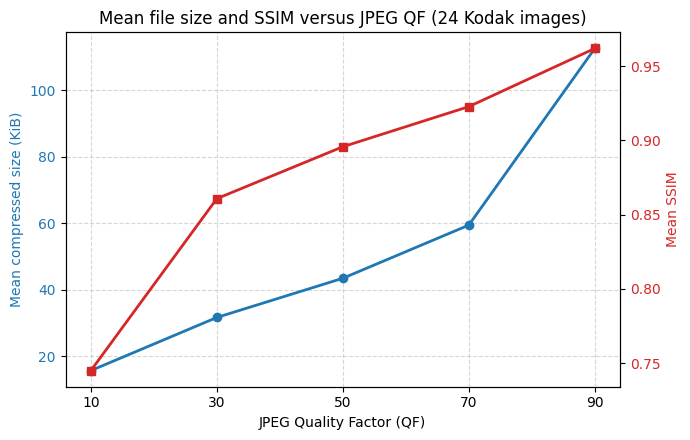

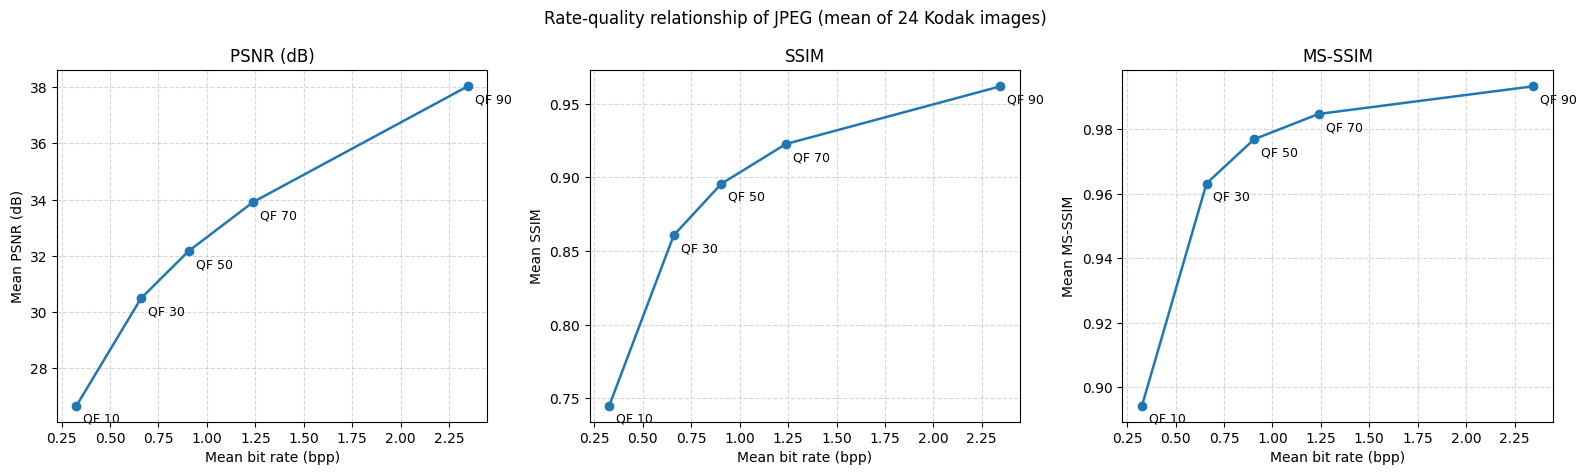

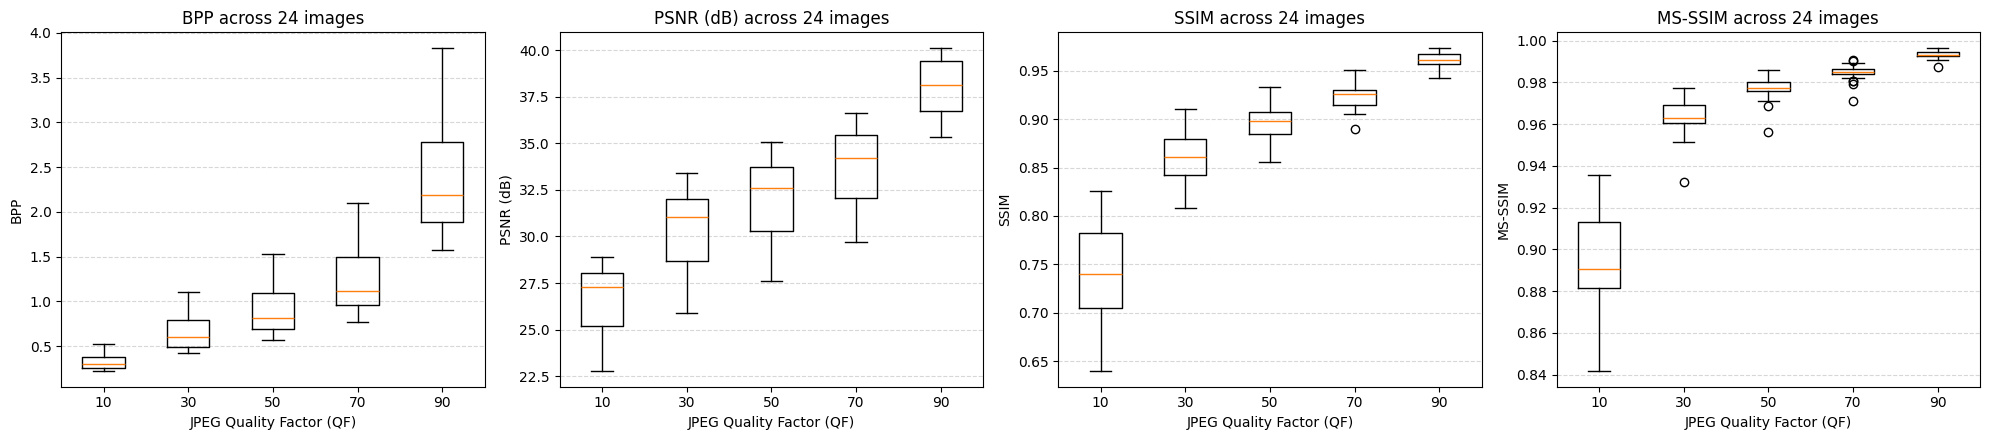

In [ ]:
def plot_size_ssim_vs_qf(mean):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax2 = ax.twinx()
    ax.plot(Q_FACTORS, mean["Size (KiB)"], "o-", color="tab:blue", linewidth=2)
    ax2.plot(Q_FACTORS, mean["SSIM"], "s-", color="tab:red", linewidth=2)
    ax.set_xlabel("JPEG Quality Factor (QF)")
    ax.set_ylabel("Mean compressed size (KiB)", color="tab:blue")
    ax2.set_ylabel("Mean SSIM", color="tab:red")
    ax.tick_params(axis="y", labelcolor="tab:blue")
    ax2.tick_params(axis="y", labelcolor="tab:red")
    ax.set_xticks(Q_FACTORS)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_title("Mean file size and SSIM versus JPEG QF (24 Kodak images)")
    fig.tight_layout()
    fig.savefig(DIR_OUTPUT / "Fig1_Size_SSIM_vs_QF.png", dpi=300)
    plt.show()

def plot_rate_quality(means, fname, title):
    metrics = ["PSNR (dB)", "SSIM", "MS-SSIM"]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    for ax, metric in zip(axes, metrics):
        for label, mean in means.items():
            ax.plot(mean["BPP"], mean[metric], "o-", label=label, linewidth=1.8)
            if len(means) == 1:
                for q in mean.index:
                    ax.annotate(f"QF {q}", (mean.loc[q, "BPP"], mean.loc[q, metric]),
                                textcoords="offset points", xytext=(5, -12), fontsize=9)
        ax.set_xlabel("Mean bit rate (bpp)")
        ax.set_ylabel(f"Mean {metric}")
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.set_title(metric)
    if len(means) > 1:
        axes[0].legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(DIR_OUTPUT / fname, dpi=300)
    plt.show()

def plot_boxplots(df):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for ax, metric in zip(axes, ["BPP", "PSNR (dB)", "SSIM", "MS-SSIM"]):
        ax.boxplot([df.loc[df["Quality"] == q, metric] for q in Q_FACTORS])
        ax.set_xticklabels(Q_FACTORS)
        ax.set_xlabel("JPEG Quality Factor (QF)")
        ax.set_ylabel(metric)
        ax.set_title(f"{metric} across 24 images")
        ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    fig.tight_layout()
    fig.savefig(DIR_OUTPUT / "Fig4_Boxplots.png", dpi=300)
    plt.show()

plot_size_ssim_vs_qf(jpeg_mean)
plot_rate_quality({"JPEG": jpeg_mean}, "Fig2_Rate_Quality_JPEG.png", "Rate-quality relationship of JPEG (mean of 24 Kodak images)")
plot_boxplots(jpeg_df)

## 8. Perbandingan visual dengan ROI zoom

Tiga gambar dipilih otomatis dari ukuran JPEG pada QF 70 (terkecil, median, terbesar = detail rendah, sedang, tinggi). ROI adalah jendela `CROP_SIZE × CROP_SIZE` dengan varians luminansi tertinggi, supaya artefak terlihat. Tulis aturan ini di Method atau caption.

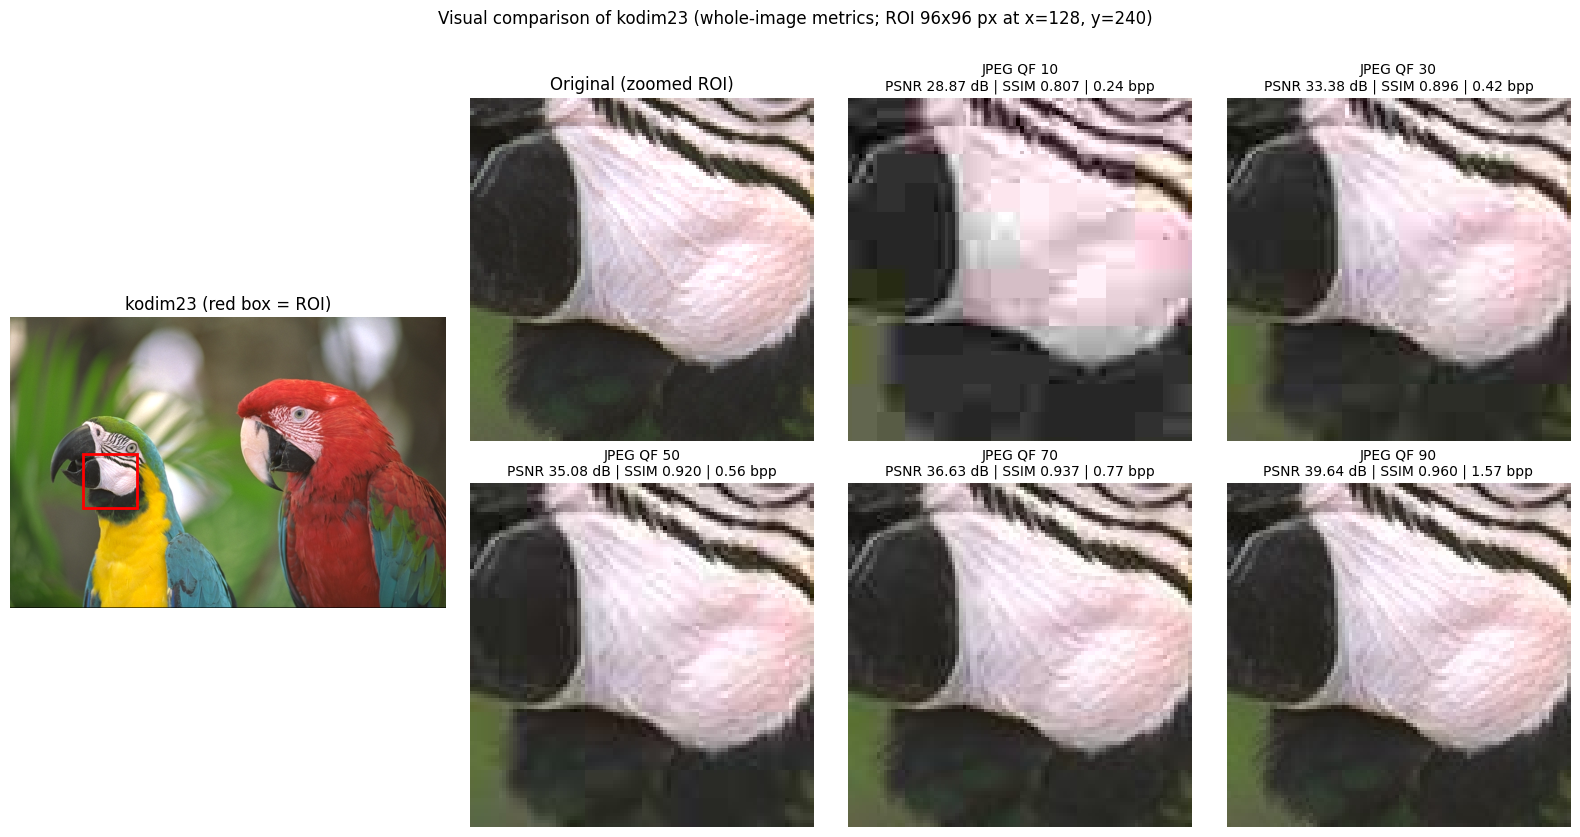

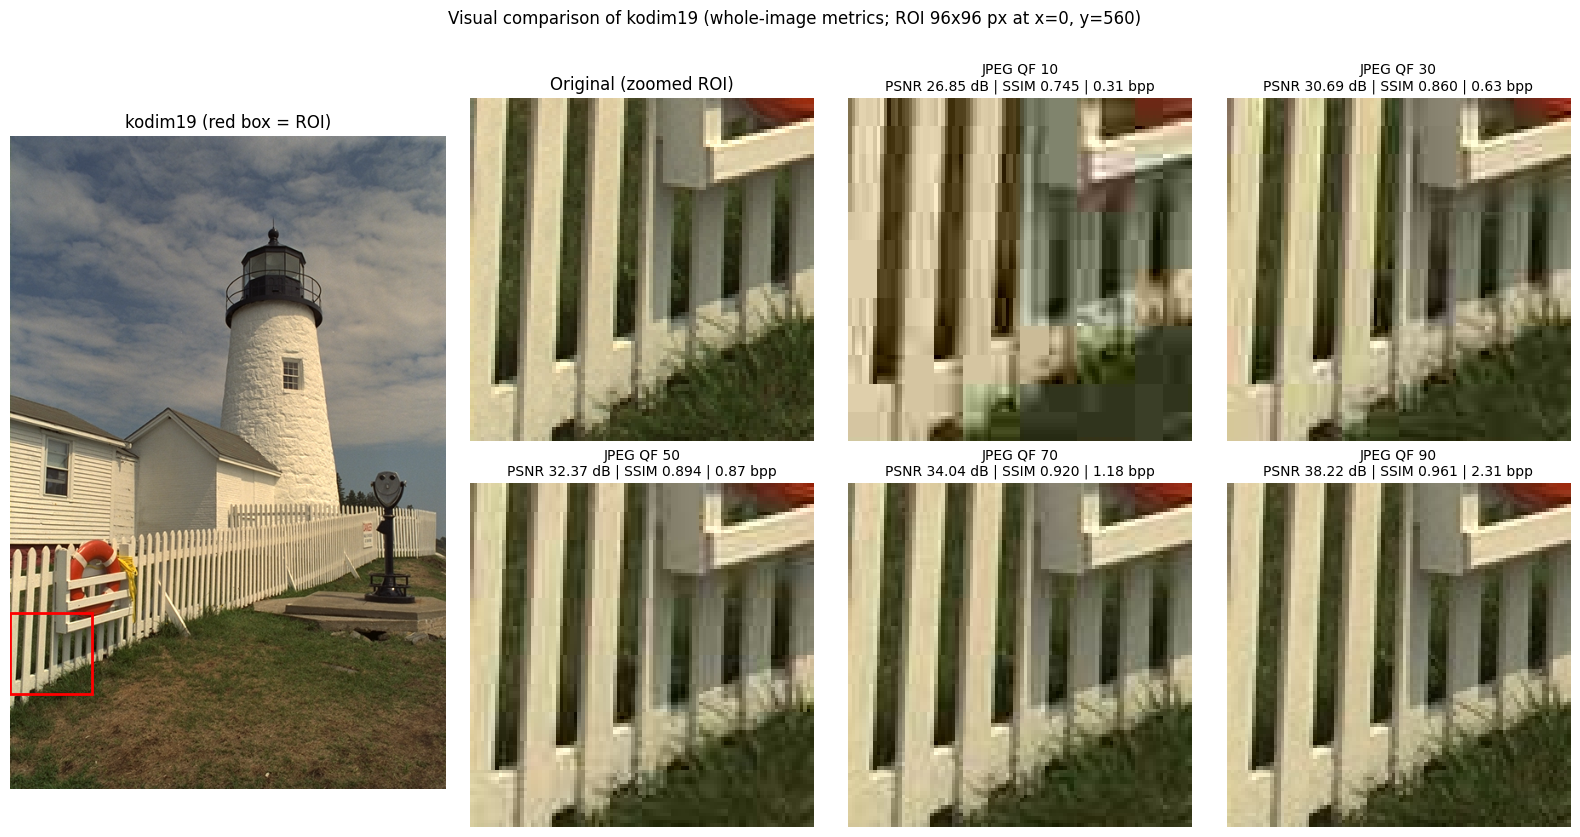

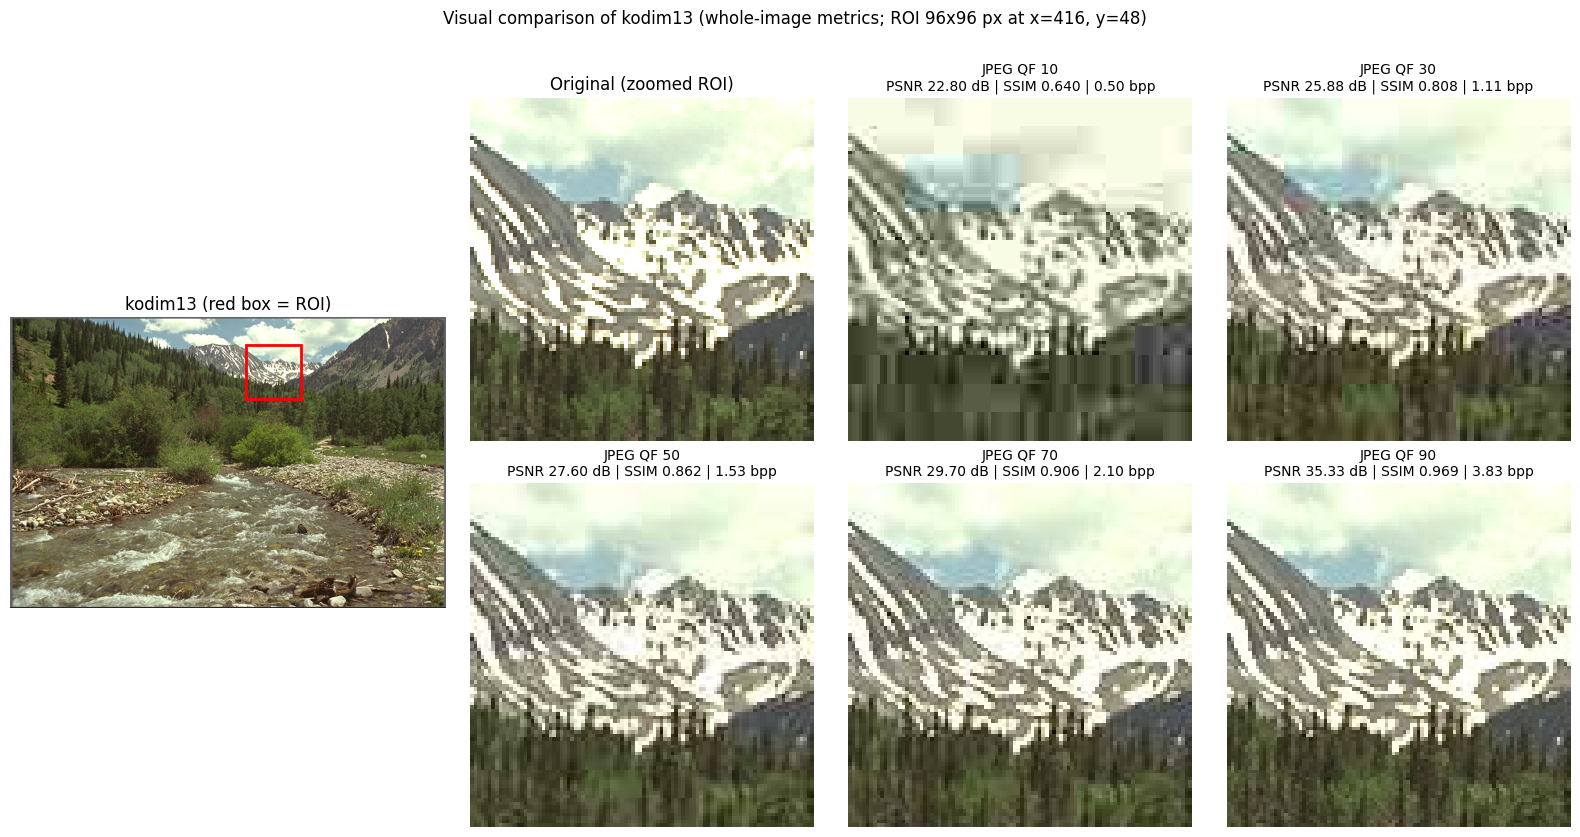

In [ ]:
def pick_roi(rgb, size=CROP_SIZE, stride=16):
    gray = rgb.mean(axis=2)
    best, pos = -1.0, (0, 0)
    for y in range(0, gray.shape[0] - size + 1, stride):
        for x in range(0, gray.shape[1] - size + 1, stride):
            v = gray[y:y + size, x:x + size].var()
            if v > best:
                best, pos = v, (x, y)
    return pos

def create_visual_comparisons(df, names=None):
    if names is None:
        q70 = df[df["Quality"] == 70].sort_values("Size (bytes)")
        names = [q70.iloc[0]["Image"], q70.iloc[len(q70) // 2]["Image"], q70.iloc[-1]["Image"]]
    for name in names:
        ref = np.asarray(Image.open(DIR_INPUT / f"{name}.png").convert("RGB"))
        x, y = pick_roi(ref)
        box = (slice(y, y + CROP_SIZE), slice(x, x + CROP_SIZE))
        fig = plt.figure(figsize=(16, 8.5))
        gs = fig.add_gridspec(2, 4, width_ratios=[1.2, 1, 1, 1])
        full = fig.add_subplot(gs[:, 0])
        panels = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(1, 4)]
        full.imshow(ref)
        full.add_patch(plt.Rectangle((x, y), CROP_SIZE, CROP_SIZE, fill=False, edgecolor="red", linewidth=2))
        full.set_title(f"{name} (red box = ROI)")
        panels[0].imshow(ref[box], interpolation="nearest")
        panels[0].set_title("Original (zoomed ROI)")
        for ax, q in zip(panels[1:], Q_FACTORS):
            rec = np.asarray(Image.open(DIR_OUTPUT / f"{name}_Q{q}.jpg").convert("RGB"))
            r = df[(df["Image"] == name) & (df["Quality"] == q)].iloc[0]
            ax.imshow(rec[box], interpolation="nearest")
            ax.set_title(f"JPEG QF {q}\nPSNR {r['PSNR (dB)']:.2f} dB | SSIM {r['SSIM']:.3f} | {r['BPP']:.2f} bpp", fontsize=10)
        for ax in [full] + panels:
            ax.axis("off")
        fig.suptitle(f"Visual comparison of {name} (whole-image metrics; ROI {CROP_SIZE}x{CROP_SIZE} px at x={x}, y={y})")
        fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=3)
        fig.savefig(DIR_OUTPUT / f"Fig3_Visual_Comparison_{name}.png", dpi=300, bbox_inches="tight")
        plt.show()

create_visual_comparisons(jpeg_df, VISUAL_IMAGES)

## 9. Perbandingan codec: JPEG vs WebP (dan AVIF bila tersedia)

Parameter `quality` tiap codec tidak setara, jadi bandingkan pada kurva bpp terhadap kualitas, bukan pada angka QF yang sama. Dijalankan tanpa library tambahan; AVIF hanya ikut jika Pillow di Colab mendukungnya (lihat `Environment.txt`).

[WEBP] kodim01.png
[WEBP] kodim02.png
[WEBP] kodim03.png
[WEBP] kodim04.png
[WEBP] kodim05.png
[WEBP] kodim06.png
[WEBP] kodim07.png
[WEBP] kodim08.png
[WEBP] kodim09.png
[WEBP] kodim10.png
[WEBP] kodim11.png
[WEBP] kodim12.png
[WEBP] kodim13.png
[WEBP] kodim14.png
[WEBP] kodim15.png
[WEBP] kodim16.png
[WEBP] kodim17.png
[WEBP] kodim18.png
[WEBP] kodim19.png
[WEBP] kodim20.png
[WEBP] kodim21.png
[WEBP] kodim22.png
[WEBP] kodim23.png
[WEBP] kodim24.png
[AVIF] kodim01.png
[AVIF] kodim02.png
[AVIF] kodim03.png
[AVIF] kodim04.png
[AVIF] kodim05.png
[AVIF] kodim06.png
[AVIF] kodim07.png
[AVIF] kodim08.png
[AVIF] kodim09.png
[AVIF] kodim10.png
[AVIF] kodim11.png
[AVIF] kodim12.png
[AVIF] kodim13.png
[AVIF] kodim14.png
[AVIF] kodim15.png
[AVIF] kodim16.png
[AVIF] kodim17.png
[AVIF] kodim18.png
[AVIF] kodim19.png
[AVIF] kodim20.png
[AVIF] kodim21.png
[AVIF] kodim22.png
[AVIF] kodim23.png
[AVIF] kodim24.png


Size (KiB)    BPP  Reduction vs RAW (%)  PSNR (dB)   SSIM  \
Codec Quality                                                              
JPEG  10            15.68  0.327                 98.64      26.67  0.745   
      30            31.67  0.660                 97.25      30.49  0.861   
      50            43.47  0.906                 96.23      32.17  0.896   
      70            59.46  1.239                 94.84      33.92  0.923   
      90           112.62  2.346                 90.22      38.03  0.962   
WEBP  10            14.22  0.296                 98.77      29.15  0.807   
      30            24.61  0.513                 97.86      31.44  0.873   
      50            34.65  0.722                 96.99      33.24  0.907   
      70            44.85  0.934                 96.11      34.69  0.928   
      90            96.50  2.010                 91.62      39.56  0.971   
AVIF  10             4.38  0.091                 99.62      26.32  0.704   
      30            13.79  0.287                 98.80      30.20  0.839   
      50            32.41  0.675                 97.19      34.19  0.920   
      70            61.58  1.283                 94.65      37.87  0.958   
      90           127.46  2.655                 88.94      41.77  0.983   

               MS-SSIM  
Codec Quality           
JPEG  10         0.894  
      30         0.963  
      50         0.977  
      70         0.985  
      90         0.993  
WEBP  10         0.940  
      30         0.964  
      50         0.975  
      70         0.982  
      90         0.993  
AVIF  10         0.882  
      30         0.951  
      50         0.979  
      70         0.990  
      90         0.996

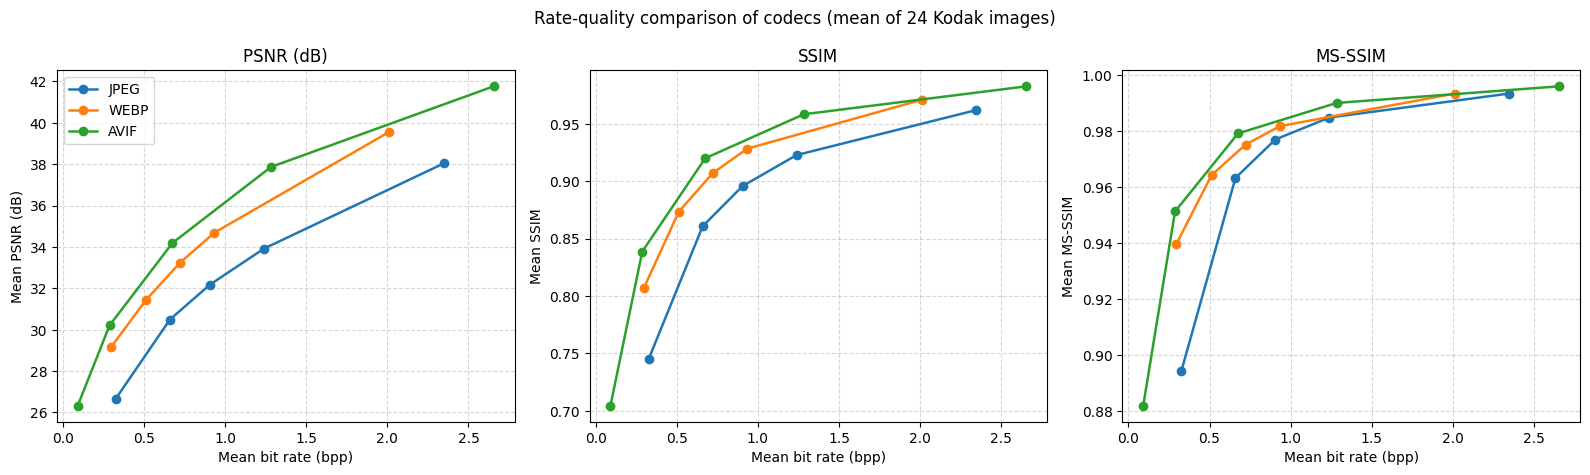

In [ ]:
CODECS = ["WEBP"] + (["AVIF"] if features.check("avif") else [])
codec_df = pd.concat([jpeg_df] + [run_codec(c, image_files) for c in CODECS], ignore_index=True)
codec_df.drop(columns=["Subsampling"]).to_csv("Detailed_Results_Codecs.csv", index=False)

codec_means = {}
for codec, sub in codec_df.groupby("Codec", sort=False):
    codec_means[codec], _ = summarize(sub)
    codec_means[codec] = codec_means[codec].loc[Q_FACTORS]

table = pd.concat({k: v.round(DEC) for k, v in codec_means.items()}, names=["Codec"])
display(table)
table.to_csv("Codec_Comparison.csv")
plot_rate_quality(codec_means, "Fig5_Codec_Comparison.png", "Rate-quality comparison of codecs (mean of 24 Kodak images)")

## 10. Kumpulkan hasil dan unduh

In [ ]:
OUT = Path("hasil_eksperimen")
OUT.mkdir(exist_ok=True)
for p in list(Path(".").glob("*.csv")) + list(Path(".").glob("Environment.txt")) + list(DIR_OUTPUT.glob("*.png")):
    shutil.copy(p, OUT)
shutil.make_archive("hasil_eksperimen", "zip", OUT)
print(sorted(p.name for p in OUT.iterdir()))
try:
    from google.colab import files
    files.download("hasil_eksperimen.zip")
except ImportError:
    pass

['Dataset_Validation.csv', 'Detailed_Results_JPEG.csv', 'Environment.txt', 'Fig1_Size_SSIM_vs_QF.png', 'Fig2_Rate_Quality_JPEG.png', 'Fig3_Visual_Comparison_kodim13.png', 'Fig3_Visual_Comparison_kodim19.png', 'Fig3_Visual_Comparison_kodim23.png', 'Fig4_Boxplots.png', 'Marginal_Efficiency.csv', 'Statistical_Tests.csv', 'Table1_Mean.csv', 'Table2_SD.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>